# EDA ON RETAIL SALES DATA

Objective : Perform a thorough Exploratory Data Analysis on a retail sales dataset to
uncover patterns, customer behaviour trends, and actionable business insights.


In [1]:
%pip install pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## Load the Dataset

In [3]:
df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## Check Dataset Shape

In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1000, 9)


## Display Column Names

In [5]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')


## Check Missing Values

In [6]:
df.isnull()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
995,False,False,False,False,False,False,False,False,False
996,False,False,False,False,False,False,False,False,False
997,False,False,False,False,False,False,False,False,False
998,False,False,False,False,False,False,False,False,False


In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


## Data Types

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB


## Descriptive Statistics

In [9]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


## Mean

In [10]:
print("MEAN:")
print(df.mean(numeric_only=True))


MEAN:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64


## Median

In [11]:
print("\nMEDIAN:")
print(df.median(numeric_only=True))


MEDIAN:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64


## Mode

In [12]:
print("\nMODE:")
print(df.mode(numeric_only=True))


MODE:
     Transaction ID   Age  Quantity  Price per Unit  Total Amount
0                 1  43.0       4.0            50.0          50.0
1                 2  64.0       NaN             NaN           NaN
2                 3   NaN       NaN             NaN           NaN
3                 4   NaN       NaN             NaN           NaN
4                 5   NaN       NaN             NaN           NaN
..              ...   ...       ...             ...           ...
995             996   NaN       NaN             NaN           NaN
996             997   NaN       NaN             NaN           NaN
997             998   NaN       NaN             NaN           NaN
998             999   NaN       NaN             NaN           NaN
999            1000   NaN       NaN             NaN           NaN

[1000 rows x 5 columns]


## Standrad Deviation

In [13]:
print("\nSTANDARD DEVIATION:")
print(df.std(numeric_only=True))


STANDARD DEVIATION:
Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


## Time Series Analysis

## Monthly Sales Trend

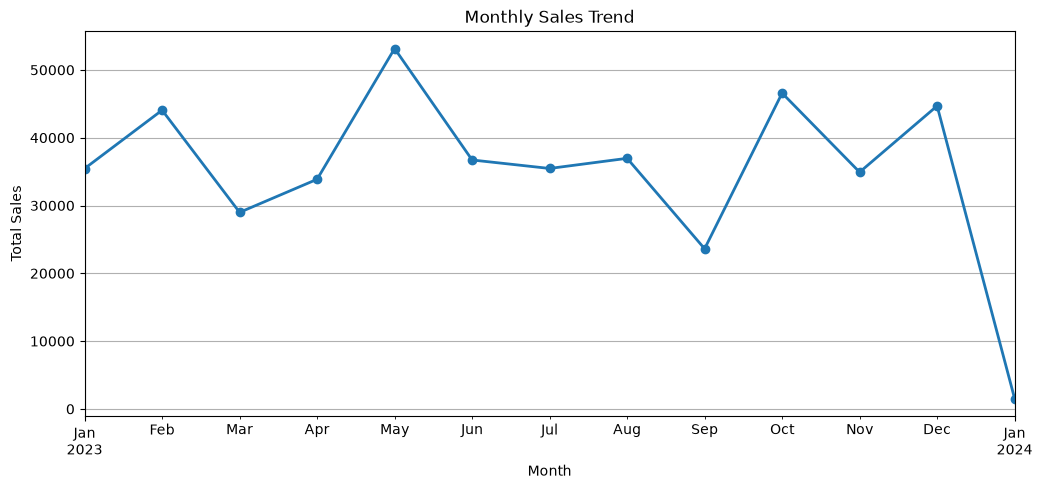

In [14]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Calculate monthly sales
monthly_sales = df.groupby(
    df["Date"].dt.to_period("M")
)["Total Amount"].sum()

# Plot monthly sales
plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o", linewidth=2)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

### Monthly Sales Observation

- May 2023 recorded the highest monthly sales.
- September 2023 had the lowest sales among the complete months of 2023.
- Monthly sales fluctuated throughout the year.
- January 2024 shows very low sales, possibly due to incomplete monthly data.

## Quarterly Sales Trend

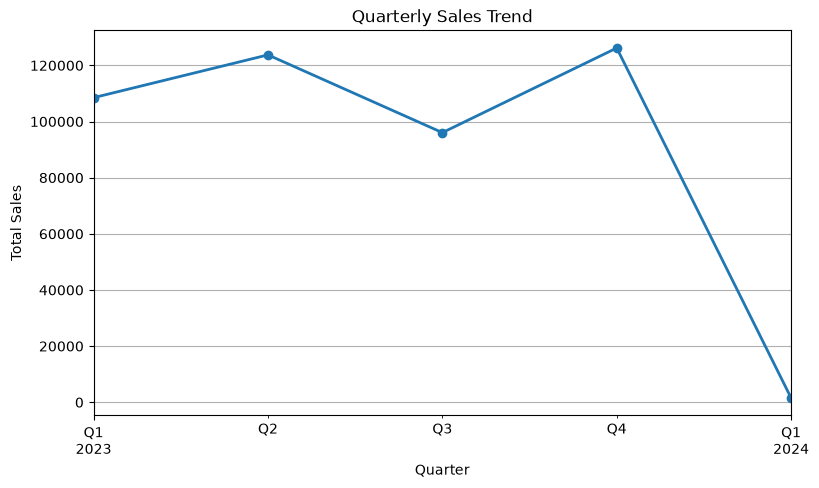

In [15]:
# Calculate quarterly sales
quarterly_sales = df.groupby(
    df["Date"].dt.to_period("Q")
)["Total Amount"].sum()

# Plot quarterly sales
plt.figure(figsize=(9, 5))
quarterly_sales.plot(marker="o", linewidth=2)

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

### Quarterly Sales Observation

- Q4 2023 recorded the highest quarterly sales.
- Q3 2023 recorded the lowest quarterly sales in 2023.
- Quarterly sales fluctuated throughout the year.
- Q1 2024 shows very low sales, possibly due to incomplete quarterly data.

## Customer Demographics

## Age Distribution

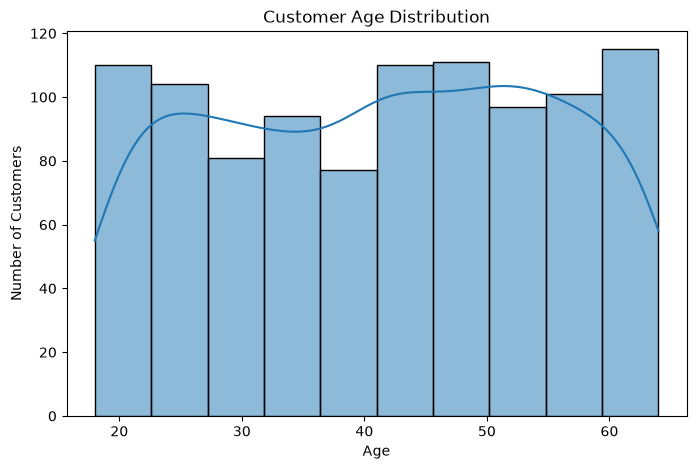

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Age"], bins=10, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

### Observation

- Customer ages range approximately from 18 to 64 years.
- Customers are distributed across a wide range of ages.
- The 60–64 age range shows a relatively high frequency.
- The age distribution is fairly balanced, without a single dominant age range.

## Customer Age Group Analysis

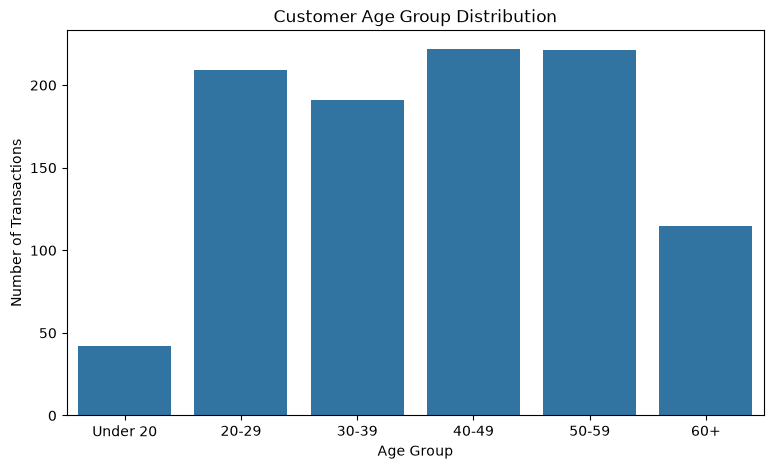

In [17]:
age_bins = [0, 20, 30, 40, 50, 60, 100]
age_labels = ["Under 20", "20-29", "30-39", "40-49", "50-59", "60+"]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_group_counts = df["Age Group"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
sns.barplot(x=age_group_counts.index, y=age_group_counts.values)

plt.title("Customer Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")

plt.show()

### Observation

- The 40–49 and 50–59 age groups recorded the highest transaction counts.
- The 20–29 age group also contributed a significant number of transactions.
- Customers under 20 recorded the fewest transactions.
- Customers aged 20–59 account for the majority of transactions.

## Gender Distribution

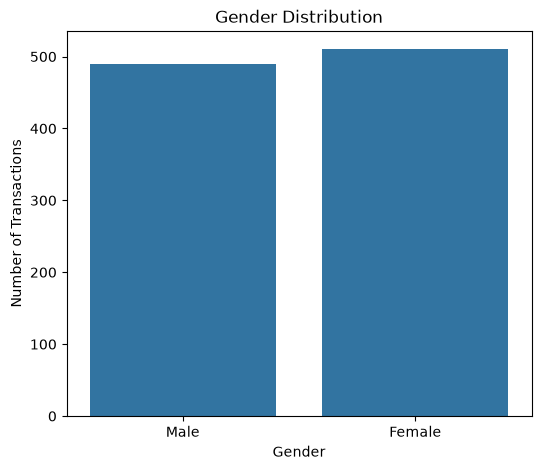

In [18]:
plt.figure(figsize=(6, 5))

sns.countplot(x="Gender", data=df)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")

plt.show()

### Observation

- Female customers accounted for approximately 51% of transactions.
- Male customers accounted for approximately 49% of transactions.
- Female customers recorded slightly more transactions than male customers.
- The gender distribution is nearly balanced, indicating similar participation from both groups.

## Product Analysis

## Top 10 Best-Selling Products

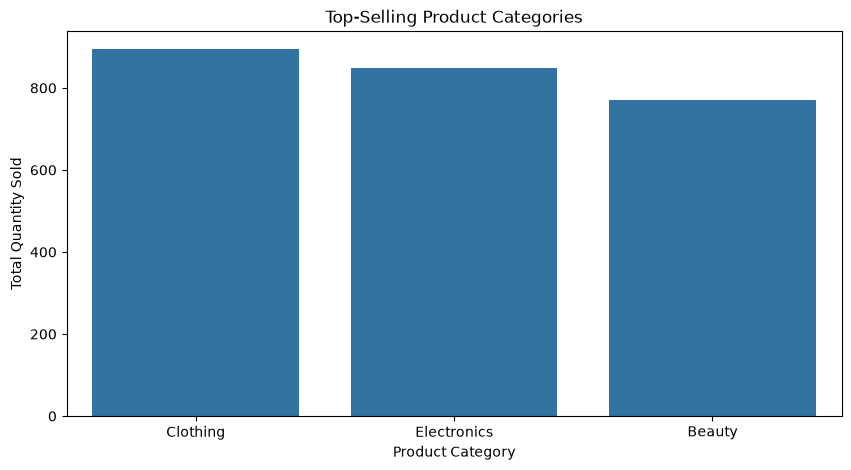

In [19]:
# Calculate total quantity sold by product category
top_products = df.groupby("Product Category")["Quantity"].sum()

# Select top 10 categories
top_products = top_products.sort_values(ascending=False).head(10)

# Plot bar chart
plt.figure(figsize=(10, 5))

sns.barplot(x=top_products.index, y=top_products.values)

plt.title("Top-Selling Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")

plt.show()

### Observation

- Clothing recorded the highest quantity sold, approximately 900 units.
- Electronics ranked second with approximately 850 units sold.
- Beauty recorded the lowest quantity sold, approximately 770 units.
- Clothing leads in sales volume, indicating strong demand for this category.

## Revenue by Product Category

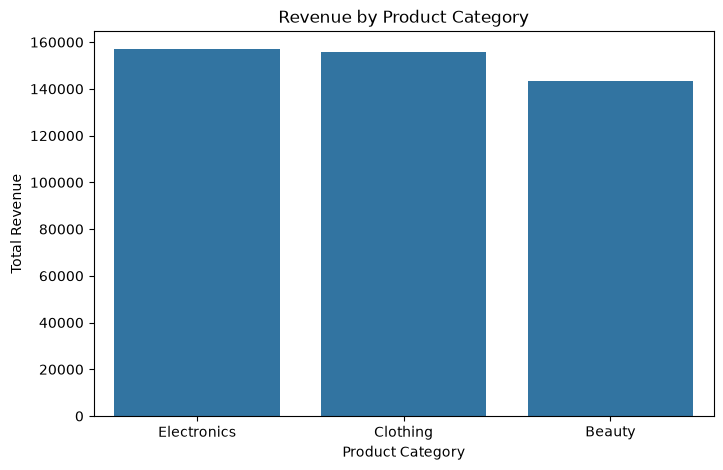

In [20]:
category_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(x=category_revenue.index, y=category_revenue.values)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")

plt.show()

### Observation

- Electronics generated the highest revenue, approximately 157,000.
- Clothing ranked second with approximately 156,000 in revenue.
- Beauty generated the lowest revenue, approximately 143,000.
- Electronics earned slightly more revenue than Clothing despite selling fewer units.

## Heatmap

## Correlation Matrix 

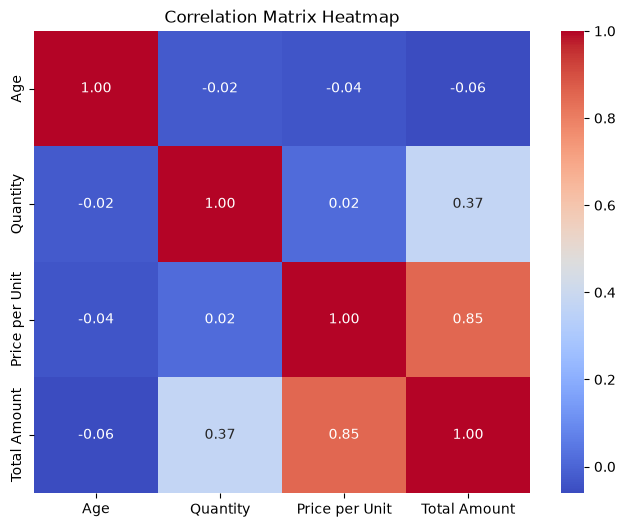

In [21]:
# Select numerical variables
numeric_columns = df[["Age", "Quantity", "Price per Unit", "Total Amount"]]

# Calculate correlation matrix
correlation_matrix = numeric_columns.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix Heatmap")
plt.show()

### Observation

- Price per Unit and Total Amount show a strong positive correlation of 0.85.
- Quantity and Total Amount have a moderate positive correlation of 0.37.
- Age has very weak correlations with the other numerical variables.
- Price per Unit has a stronger relationship with Total Amount than Quantity does.

## Product Category Sales Performance – Bubble Chart

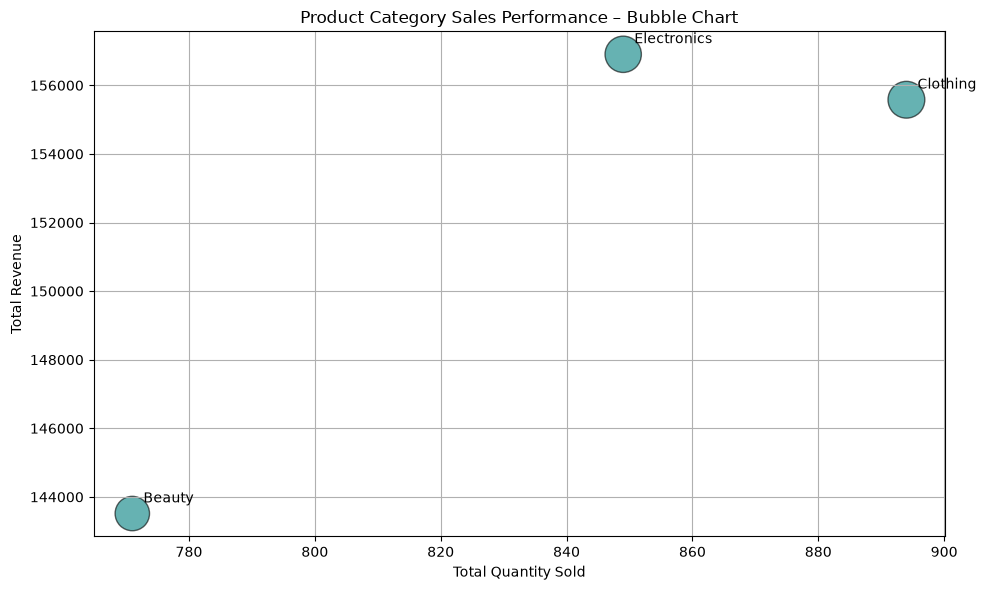

In [22]:
# Calculate product category performance
bubble_data = df.groupby("Product Category").agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Total Amount", "sum"),
    Transactions=("Transaction ID", "count")
).reset_index()

# Create bubble chart
plt.figure(figsize=(10, 6))

plt.scatter(
    bubble_data["Total_Quantity"],
    bubble_data["Total_Revenue"],
    s=bubble_data["Transactions"] * 2,
    alpha=0.6,
    color="teal",
    edgecolors="black"
)

# Add product category labels
for i in range(len(bubble_data)):
    plt.annotate(
        bubble_data["Product Category"][i],
        (
            bubble_data["Total_Quantity"][i],
            bubble_data["Total_Revenue"][i]
        ),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.title("Product Category Sales Performance – Bubble Chart")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Total Revenue")
plt.grid(True)
plt.tight_layout()

plt.show()

### Bubble Chart Observation

- Clothing recorded the highest quantity sold, approximately 894 units.
- Electronics generated the highest revenue, approximately 157,000.
- Beauty recorded the lowest sales quantity and revenue among all categories.
- Electronics generated more revenue than Clothing despite selling fewer units.

## Conclusion

- Retail sales showed noticeable fluctuations across different months and quarters.
- May 2023 recorded the highest monthly sales, while Q4 2023 achieved the highest quarterly revenue.
- Customer demographics and product category analysis helped identify purchasing patterns.
- The analysis provides useful insights for improving sales performance and business planning.

## Business Recommendations

1. **Improve Inventory Planning:** Increase stock availability before high-sales periods such as May and Q4 to meet customer demand.

2. **Boost Sales During Low-Performing Months:** Introduce special discounts and promotional campaigns during weaker sales periods, such as September.

3. **Focus on High-Revenue Product Categories:** Prioritize inventory and marketing for categories generating higher revenue while developing strategies to improve weaker categories.

4. **Target Customers Based on Demographics:** Use age group and gender analysis to create targeted marketing campaigns and personalized product promotions.

5. **Monitor Sales Performance Regularly:** Track monthly and quarterly sales trends to identify changes in customer demand and improve business decisions.